# Notebook 4 — Résultats, analyse des erreurs et limites

Ce notebook présente les résultats finaux du projet et les analyse. Il ne réentraîne aucun modèle : il relit les
sorties des commandes décrites dans le README (entraînement, évaluation, analyses) et les met en perspective.

**Résultat principal.** Sur le jeu de test (100 000 simulations jamais vues, température arrondie à 0,01 °C comme
dans l'énoncé), le CNN 1D prédit le HLC avec une erreur relative moyenne de **8,4 %** (R² = 0,42), contre 11,1 % en
prédisant simplement la moyenne. Il est le meilleur des modèles comparés sur cinq cibles sur six, avec un avantage
net sur HLC$_{ext}$. Les constantes de temps restent peu prédictibles (R² ≤ 0,25). Ce plafond s'explique par la
physique : les constantes de temps cibles (environ 11 à 49 h) dépassent toutes la fenêtre de mesure de 8 h.

| Section | Contenu |
|---|---|
| 1 | Protocole d'évaluation |
| 2 | Entraînement du CNN |
| 3 | Résultats sur le test |
| 4 | Où le modèle se trompe |
| 5 | Sensibilité à la résolution du capteur |
| 6 | Pourquoi ce plafond ? Analyse physique |
| 7 | Limites et lien avec la méthode de coEnergy |
| 8 | Conclusion et perspectives |

In [1]:
import json

import numpy as np
import pandas as pd
import torch

from thermal_id import plots
from thermal_id.baseline import LinearBaseline, batch_features
from thermal_id.data import RAW_TARGETS, Normalizer
from thermal_id.paths import PROCESSED_DIR, RESULTS_DIR, ROOT, RUNS_DIR

PROCESSED_T2 = ROOT / "data" / "processed_t2"     # T arrondi à 0,01 °C (format de l'énoncé)
RESULTS_T2 = RESULTS_DIR / "t2"
plots.apply_style()


def load_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


def table(reports: dict, metric: str, digits: int = 2) -> pd.DataFrame:
    # Tableau modèles x cibles pour une métrique (mape, r2 ou mae).
    return pd.DataFrame({name: {t: rep[t][metric] for t in RAW_TARGETS} for name, rep in reports.items()}).T.round(digits)


final = load_json(RESULTS_T2 / "final_test.json")
final_pred = torch.load(RESULTS_T2 / "final_test_pred.pt", weights_only=True)
print(f"test : {final['n']} simulations, batches {final['test_batches']}, T arrondi à {final['t_decimals']} décimales")

test : 100000 simulations, batches [19, 20], T arrondi à 2 décimales


## 1. Protocole d'évaluation

| Élément | Choix | Raison |
|---|---|---|
| Découpage | train : batches 1–16 (800 000) ; validation : 17–18 (100 000) ; test : 19–20 (100 000) | découpage par batch, sans tirage de simulations : aucune fuite entre ensembles (chaque simulation est un bâtiment distinct, vérifié dans le notebook 1) |
| Entrées | T arrondi à 0,01 °C, U marche/arrêt | format de l'exemple de chargement de l'énoncé, proche d'un capteur réel |
| Normalisation | statistiques du train uniquement | rien n'est appris sur la validation ni le test |
| Choix du modèle | perte de validation (MSE des cibles normalisées), fixée à l'avance | un seul critère, décidé avant de voir les résultats |
| Test | une seule évaluation, après avoir figé tous les modèles | mesure non biaisée de la performance |
| Métriques | MAE (unités physiques), MAPE (%), R², par cible ; MAPE par famille d'excitation | une erreur absolue, une relative, et la part de variance expliquée |

**Modèles comparés**, tous ajustés sur le même train et évalués sur les mêmes simulations :

1. **Moyenne du train** : prédit toujours la même valeur. C'est la référence triviale : un modèle utile doit faire mieux.
2. **Régression linéaire de degré 2** sur 36 descripteurs physiques (forme de la réponse et identification modale, notebook 2).
3. **MLP sur les mêmes 36 descripteurs** : teste si une non-linéarité suffit, sans lire la courbe complète.
4. **CNN 1D** (notebook 3) : lit directement les deux séries de 480 pas.

Contrainte physique : le modèle prédit HLC$_{mit}$ et HLC$_{ext}$, et le HLC est leur somme. La relation
$\text{HLC} = \text{HLC}_{mit} + \text{HLC}_{ext}$ est donc respectée exactement, par construction.

## 2. Entraînement du CNN

Configuration de l'entraînement retenu :

In [2]:
cfg = load_json(RUNS_DIR / "cnn_t2_400k" / "config.json")
pd.Series({
    "simulations d'entraînement": f"{cfg['n_train']:,}".replace(",", " ") + " (tirées des batches 1–16)",
    "epochs": cfg["epochs"],
    "taille des lots": cfg["batch_size"],
    "optimiseur": f"AdamW, weight decay {cfg['weight_decay']}",
    "taux d'apprentissage": f"one-cycle, maximum {cfg['max_lr']}",
    "écrêtage du gradient": cfg["grad_clip"],
    "architecture": f"stem + {len(cfg['model']['widths'])} blocs résiduels, largeurs {cfg['model']['widths']}, "
                    f"noyau {cfg['model']['kernel_size']}, {cfg['model']['norm']}norm",
    "tête": f"pooling moyenne + max, MLP {cfg['model']['head_hidden']}, dropout {cfg['model']['dropout']}",
    "perte": "MSE sur les 5 cibles normalisées (HLC_mit, HLC_ext, log tau_b, log tau_n, log tau_inf)",
}, name="valeur").to_frame()

,valeur
simulations d'entraînement,400 000 (tirées des batches 1–16)
epochs,10
taille des lots,256
optimiseur,"AdamW, weight decay 0.0001"
taux d'apprentissage,"one-cycle, maximum 0.002"
écrêtage du gradient,1.0
architecture,"stem + 6 blocs résiduels, largeurs [32, 32, 64..."
tête,"pooling moyenne + max, MLP 128, dropout 0.1"
perte,"MSE sur les 5 cibles normalisées (HLC_mit, HLC..."


Deux entraînements identiques sont comparés : l'un sur T exact (précision de stockage, environ $10^{-6}$ °C), l'autre
sur T arrondi à 0,01 °C. La ligne pointillée grise donne la perte de la régression linéaire sur la validation.

perte de validation de la régression linéaire : 0.829
T exact            perte val finale 0.744 | perte train finale 0.736
T arrondi 0,01 °C  perte val finale 0.764 | perte train finale 0.755


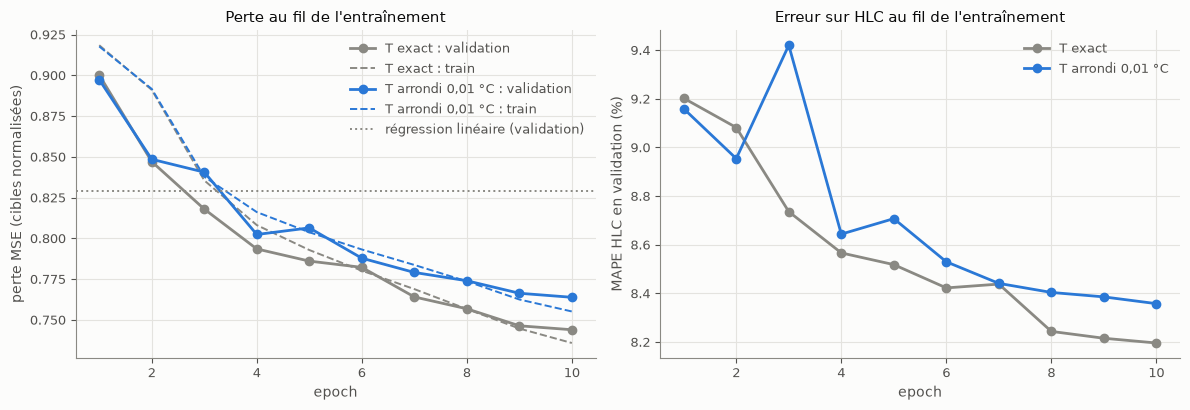

In [3]:
# perte de validation de la régression linéaire, pour situer le CNN
norm_t2 = Normalizer.load(PROCESSED_T2 / "normalizer.json")
manifest = load_json(PROCESSED_T2 / "manifest.json")
val_feats = [batch_features(PROCESSED_T2, k) for k in manifest["splits"]["val"]]
X_val = torch.cat([f["X"] for f in val_feats])
z_val = norm_t2.targets(torch.cat([f["y"] for f in val_feats]))
lin = LinearBaseline(**torch.load(RESULTS_T2 / "baseline_deg2.pt", weights_only=True)["model"])
lin_val_loss = torch.nn.functional.mse_loss(lin.predict(X_val), z_val).item()

histories = {
    "T exact": load_json(RUNS_DIR / "cnn_cpu_400k" / "history.json"),
    "T arrondi 0,01 °C": load_json(RUNS_DIR / "cnn_t2_400k" / "history.json"),
}
fig = plots.learning_curves(histories, baseline_loss=lin_val_loss)
print(f"perte de validation de la régression linéaire : {lin_val_loss:.3f}")
for name, h in histories.items():
    print(f"{name:<18} perte val finale {h[-1]['val_loss']:.3f} | perte train finale {h[-1]['train_loss']:.3f}")

**Lecture.**
- La perte de validation baisse à chaque epoch, sans jamais remonter durablement, et reste très proche de la perte
  d'entraînement : **il n'y a pas de sur-apprentissage**. Le modèle de l'epoch 10 est le meilleur.
- Le CNN passe sous la régression linéaire dès la 3e ou 4e epoch.
- La courbe descend encore à la fin. Plus de données (800 000 simulations au lieu de 400 000) ou plus d'epochs
  apporteraient un petit gain supplémentaire ; cela demande un GPU (environ 5 h sur le CPU utilisé ici).
- Entraîné sur T arrondi, le modèle suit presque la même trajectoire : la résolution de 0,01 °C coûte peu
  (section 5).

## 3. Résultats sur le test

Évaluation unique, sur les batches 19–20 (100 000 simulations), après avoir figé les quatre modèles.
Commande : `uv run python -m thermal_id.final --processed-dir data/processed_t2 --results-dir results/t2 --cnn runs/cnn_t2_400k/best.pt`.

In [4]:
reports = {name: m["report"] for name, m in final["models"].items()}
print("MAPE (%) : plus bas = mieux")
display(table(reports, "mape"))
print("R² : plus haut = mieux")
display(table(reports, "r2", 3))
print("MAE (W/K pour HLC et H_b, heures pour les tau)")
display(table(reports, "mae"))

MAPE (%) : plus bas = mieux


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
moyenne du train,11.13,19.02,12.81,15.98,14.22,18.99
régression linéaire (degré 2),8.57,16.07,10.80,15.37,12.59,18.42
MLP sur descripteurs,8.37,16.00,10.00,15.09,12.31,18.17
CNN 1D (modèle retenu),8.36,15.83,9.35,14.94,12.32,18.03


R² : plus haut = mieux


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
moyenne du train,-0.000,-0.000,-0.000,-0.010,-0.009,-0.014
régression linéaire (degré 2),0.387,0.252,0.266,0.062,0.208,0.046
MLP sur descripteurs,0.414,0.259,0.363,0.094,0.243,0.071
CNN 1D (modèle retenu),0.416,0.270,0.440,0.115,0.245,0.087


MAE (W/K pour HLC et H_b, heures pour les tau)


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
moyenne du train,25.25,21.44,13.83,7.90,1.57,5.85
régression linéaire (degré 2),19.57,18.27,11.73,7.62,1.39,5.68
MLP sur descripteurs,19.13,18.19,10.89,7.49,1.36,5.61
CNN 1D (modèle retenu),19.10,18.04,10.21,7.41,1.37,5.56


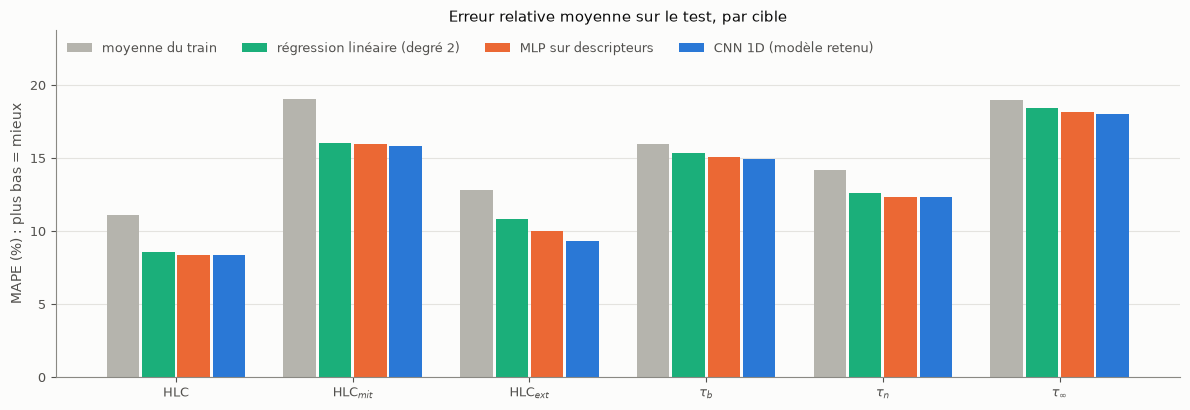

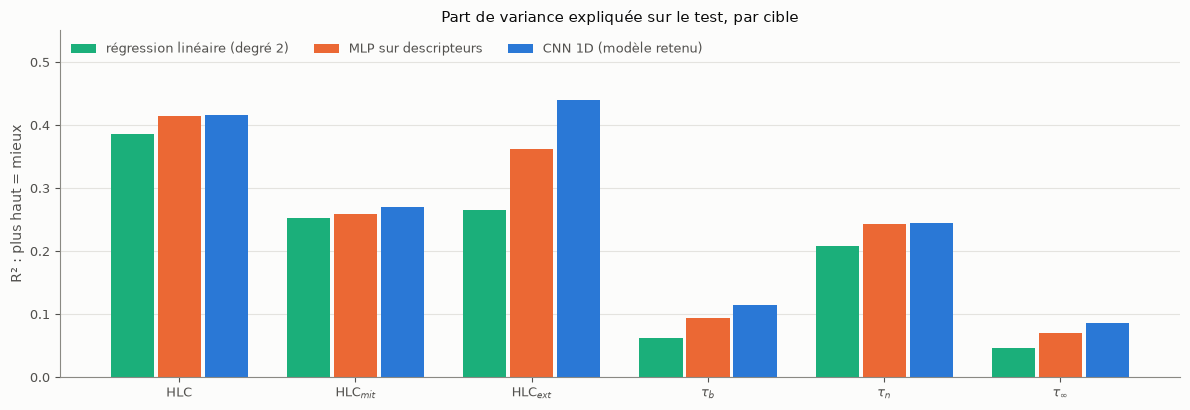

In [5]:
fig = plots.metric_by_model(reports, "mape", title="Erreur relative moyenne sur le test, par cible")
fig = plots.metric_by_model({k: v for k, v in reports.items() if k != "moyenne du train"}, "r2",
                            title="Part de variance expliquée sur le test, par cible")

In [6]:
# comparaison validation / test pour le modèle retenu : le choix sur la validation a-t-il « collé » à celle-ci ?
val_cnn = load_json(RESULTS_DIR / "cnn_t2_400k_val.json")["report"]
pd.DataFrame({"validation": {t: val_cnn[t]["mape"] for t in RAW_TARGETS},
              "test": {t: reports["CNN 1D (modèle retenu)"][t]["mape"] for t in RAW_TARGETS}}).T.round(2)

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
validation,8.36,15.80,9.35,14.97,12.33,18.07
test,8.36,15.83,9.35,14.94,12.32,18.03


**Lecture.**
- **Les scores de test sont identiques à ceux de validation** (écarts de quelques centièmes) : le choix du modèle
  n'a pas été optimisé sur le bruit de la validation, et ces chiffres sont fiables.
- **Le CNN est le meilleur modèle sur cinq cibles sur six** ; sur $\tau_n$, il est à égalité avec le MLP.
- **Son avance est nette sur HLC$_{ext}$** (R² 0,44 contre 0,36 pour le MLP et 0,27 pour la régression) : lire la
  courbe complète apporte surtout de l'information sur la répartition des pertes entre l'extérieur et les espaces
  mitoyens.
- **Sur le HLC, l'avance est faible** (8,36 % contre 8,37 % pour le MLP et 8,57 % pour la régression). Des
  descripteurs physiques bien choisis captent presque toute l'information disponible sur le HLC.
- **Les constantes de temps sont peu prédites** par tous les modèles (R² de 0,09 à 0,25). L'erreur moyenne reste
  pourtant modérée (7,4 h sur $\tau_b \approx 49$ h, 1,4 h sur $\tau_n \approx 11$ h), parce que ces grandeurs
  varient peu dans la population : prédire la moyenne est déjà une estimation raisonnable.

## 4. Où le modèle se trompe

### 4.1 Prédit contre réel

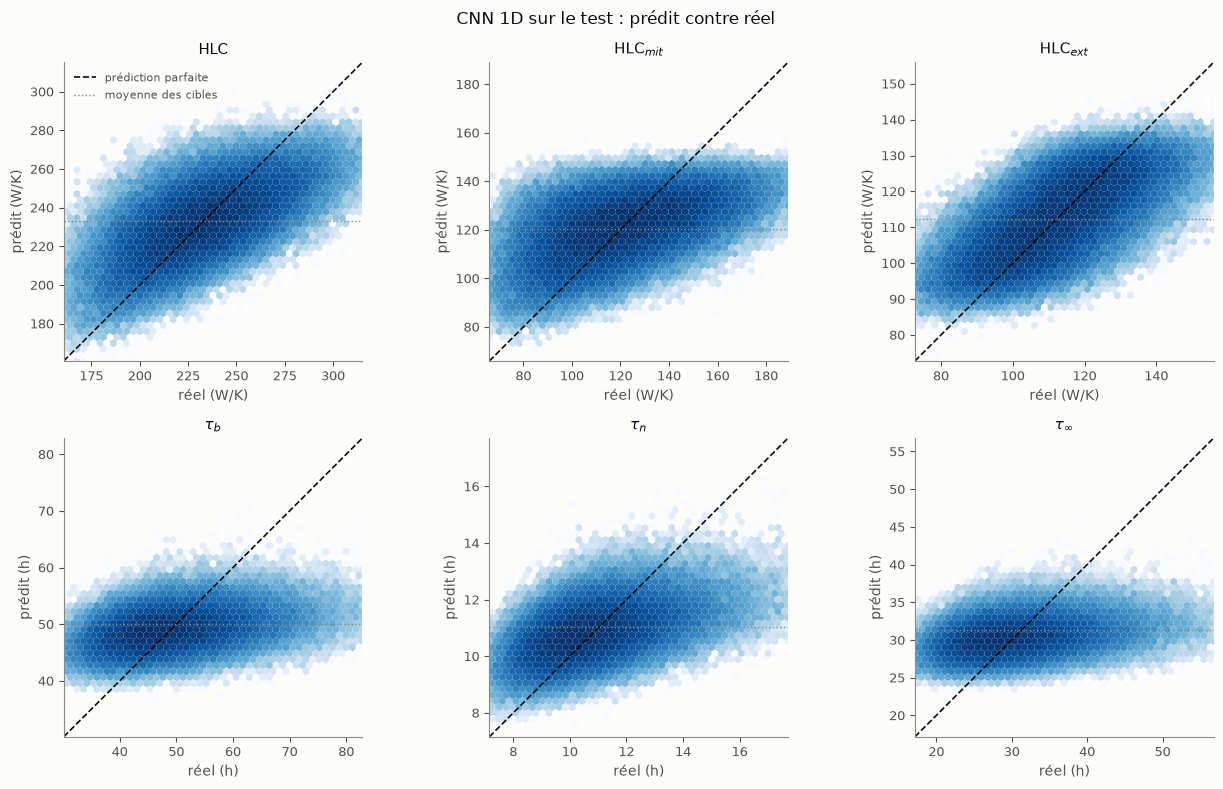

In [7]:
y = final_pred["y"].numpy()
pred_cnn = final_pred["CNN 1D (modèle retenu)"].numpy()
fig = plots.predicted_vs_true(y, pred_cnn, title="CNN 1D sur le test : prédit contre réel")

**Lecture.** Les nuages sont « aplatis » : la pente des prédictions est plus faible que celle de la diagonale. Le
modèle surestime les petites valeurs et sous-estime les grandes. C'est le comportement attendu d'un modèle entraîné à
l'erreur quadratique quand l'information est incomplète : il prédit la **moyenne des bâtiments compatibles avec la
courbe observée**. Plus l'information sur une cible est faible, plus la prédiction se rapproche de la moyenne de la
population. Sur les trois $\tau$, le nuage est presque horizontal. Ce n'est pas un défaut d'entraînement : la
section 6 montre que l'information manque dans les données elles-mêmes.

### 4.2 Erreur selon le scénario de chauffage

Le signal de chauffage (PRBS) est décrit par deux paramètres : la durée minimale des créneaux (`min_duration`, de 0
à 2 h) et la probabilité de chauffer (`p_on`, de 0,2 à 0,9). On découpe le test en cinq groupes égaux (quintiles)
selon chacun d'eux, et on sépare les simulations sans aucun chauffage.

In [8]:
models = final["models"]
pd.DataFrame({name: {"sans chauffage": m["mape_no_heat_vs_heat"]["0"]["HLC"],
                     "avec chauffage": m["mape_no_heat_vs_heat"]["1"]["HLC"]}
              for name, m in models.items()}).T.round(2).rename_axis("MAPE HLC (%)")

,sans chauffage,avec chauffage
MAPE HLC (%),,
moyenne du train,11.00,11.15
régression linéaire (degré 2),9.81,8.46
MLP sur descripteurs,9.94,8.23
CNN 1D (modèle retenu),9.30,8.27


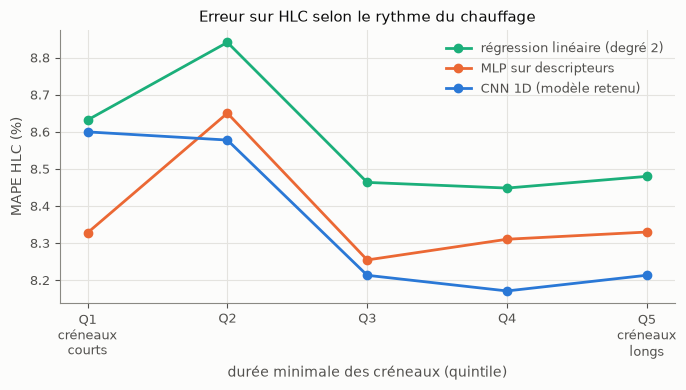

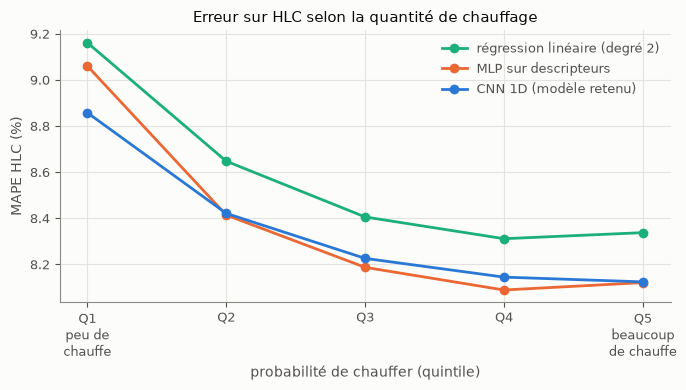

In [9]:
shown = {k: v for k, v in models.items() if k != "moyenne du train"}
fig = plots.mape_by_group(shown, "mape_by_min_duration_quintile", "HLC",
                          ["Q1\ncréneaux\ncourts", "Q2", "Q3", "Q4", "Q5\ncréneaux\nlongs"],
                          "durée minimale des créneaux (quintile)", "Erreur sur HLC selon le rythme du chauffage")
fig = plots.mape_by_group(shown, "mape_by_p_on_quintile", "HLC",
                          ["Q1\npeu de\nchauffe", "Q2", "Q3", "Q4", "Q5\nbeaucoup\nde chauffe"],
                          "probabilité de chauffer (quintile)", "Erreur sur HLC selon la quantité de chauffage")

**Lecture.**
- **Sans chauffage, l'erreur augmente** : le bâtiment n'est observé qu'en refroidissement libre depuis l'état
  initial, et la réponse au chauffage, qui porte l'essentiel de l'information sur le HLC, manque.
- **Pour le CNN, l'erreur dépend peu du scénario** dès qu'il y a du chauffage. Elle diminue légèrement quand la
  quantité de chauffage augmente : un échauffement plus fort rend la réponse plus lisible.
- **Les trois modèles réagissent de la même façon aux scénarios.** La difficulté vient de l'information contenue
  dans la mesure, pas d'une faiblesse propre à un modèle.

## 5. Sensibilité à la résolution du capteur

L'exemple de chargement de l'énoncé arrondit la température à 0,01 °C (`indoor_temperature.round(decimals=2)`).
Un premier CNN avait été entraîné sur T non arrondi (précision de stockage, environ $10^{-6}$ °C). Trois situations
sont comparées sur la validation :

1. CNN entraîné et évalué sur T exact ;
2. le même CNN, évalué sur T arrondi à 0,01 °C ;
3. un CNN réentraîné sur T arrondi (modèle retenu).

MAPE (%) en validation


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
entraîné et évalué sur T exact,8.20,15.67,9.02,14.79,12.18,17.93
"entraîné sur T exact, évalué sur T arrondi",10.09,16.87,12.42,17.59,15.49,20.71
réentraîné sur T arrondi,8.36,15.80,9.35,14.97,12.33,18.07


R² en validation


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
entraîné et évalué sur T exact,0.440,0.282,0.480,0.136,0.258,0.100
"entraîné sur T exact, évalué sur T arrondi",0.073,0.097,-0.059,-0.098,-0.123,-0.065
réentraîné sur T arrondi,0.416,0.268,0.441,0.117,0.243,0.088


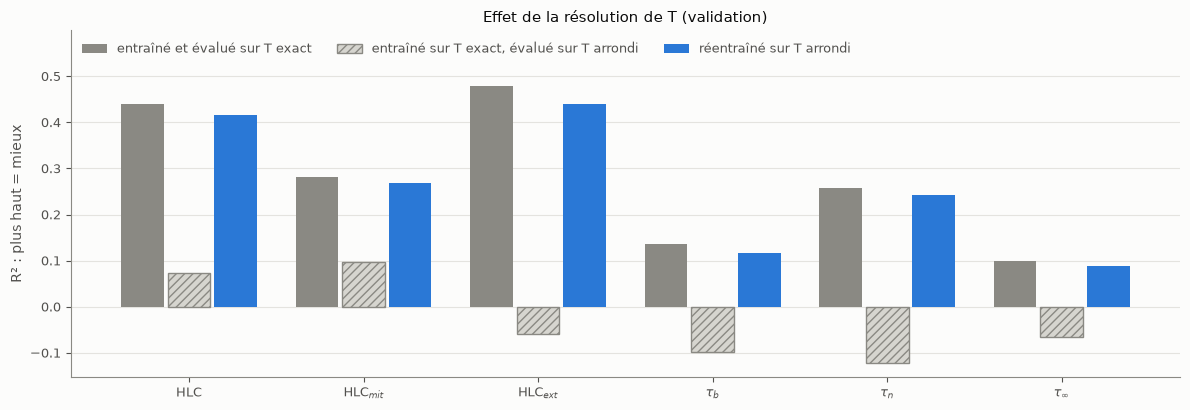

In [10]:
variants = {
    "entraîné et évalué sur T exact": load_json(RESULTS_DIR / "cnn_400k_val.json"),
    "entraîné sur T exact, évalué sur T arrondi": load_json(RESULTS_DIR / "cnn_400k_round2_val.json"),
    "réentraîné sur T arrondi": load_json(RESULTS_DIR / "cnn_t2_400k_val.json"),
}
var_reports = {k: v["report"] for k, v in variants.items()}
print("MAPE (%) en validation")
display(table(var_reports, "mape"))
print("R² en validation")
display(table(var_reports, "r2", 3))
fig = plots.metric_by_model(var_reports, "r2", title="Effet de la résolution de T (validation)")

In [11]:
def by_duration(v):
    g = v["mape_by_min_duration_quintile"]
    return {f"Q{int(k) + 1}": g[k]["HLC"] for k in sorted(g, key=int)}

rows = {k: {"sans chauffage": v["mape_no_heat_vs_heat"]["0"]["HLC"], **by_duration(v)} for k, v in variants.items()}
pd.DataFrame(rows).T.round(2).rename_axis("MAPE HLC (%) ; Q1 = créneaux courts, Q5 = créneaux longs")

,sans chauffage,Q1,Q2,Q3,Q4,Q5
"MAPE HLC (%) ; Q1 = créneaux courts, Q5 = créneaux longs",,,,,,
entraîné et évalué sur T exact,8.86,8.52,8.42,8.15,8.00,7.89
"entraîné sur T exact, évalué sur T arrondi",12.46,8.83,9.28,9.92,11.28,11.15
réentraîné sur T arrondi,9.54,8.52,8.56,8.31,8.24,8.17


In [12]:
# ordre de grandeur des variations de T d'une minute à l'autre (T exact, 20 000 simulations de validation)
from thermal_id.data import CompactBatch

b17 = CompactBatch.load(PROCESSED_DIR / "batch_17.pt")
T, U = b17.T[:20000].double(), b17.U_on[:20000]
dT = T.diff(dim=1).abs()[U[:, 1:] == U[:, :-1]]          # pas sans commutation du chauffage
print(f"variation de T en une minute (hors commutation) : médiane {dT.median():.4f} °C")
print(f"part des pas où T varie de moins de 0,01 °C      : {100 * (dT < 0.01).double().mean():.0f} %")
print(f"erreur RMS due à l'arrondi à 0,01 °C            : {(T - T.round(decimals=2)).pow(2).mean().sqrt():.4f} °C")

variation de T en une minute (hors commutation) : médiane 0.0158 °C
part des pas où T varie de moins de 0,01 °C      : 38 %
erreur RMS due à l'arrondi à 0,01 °C            : 0.0029 °C


**Lecture.**
- **Sans réentraînement, l'arrondi est très pénalisant** : le R² du HLC passe de 0,44 à 0,07, et les R² des autres
  cibles deviennent négatifs (pire que prédire la moyenne). Le premier modèle s'appuyait sur des détails de la
  courbe plus fins que 0,01 °C.
- **Pourquoi un si petit arrondi a-t-il un tel effet ?** L'erreur d'arrondi (≈ 0,003 °C en moyenne) est faible devant
  la température, mais pas devant ce qui change d'une minute à l'autre : hors commutation, T varie de 0,016 °C par
  minute en médiane, et de moins de 0,01 °C dans 38 % des pas. Arrondie, la courbe devient une suite de paliers ; les
  pentes locales, que les filtres convolutifs calculent sur quelques minutes, sont alors fausses.
- **Réentraîné sur T arrondi, le CNN retrouve presque toute sa performance** (MAPE HLC 8,36 % contre 8,20 %). La
  chute venait donc surtout de l'écart entre les données d'entraînement et les données évaluées, pas d'une perte
  d'information : le réseau apprend à lire les pentes sur des fenêtres plus longues.
- **Il reste un petit coût, concentré dans les cas « lents »** : sans chauffage (+0,7 point) et avec de longs
  créneaux (+0,3 point), là où l'information tient dans des pentes très faibles.
- **Conséquence pratique** : un modèle doit être entraîné sur des données qui ont la résolution, et idéalement le
  bruit, du capteur réel. C'est ce que fait coEnergy dans sa méthode, qui ajoute aux simulations un bruit calibré sur
  ses capteurs (section 7).

## 6. Pourquoi ce plafond ? Analyse physique

### 6.1 Les constantes de temps dépassent la fenêtre de mesure

Les définitions de l'énoncé décrivent des relaxations lentes de la masse du bâtiment. Pour un mode de constante de
temps $\tau$, la part de son évolution visible en 8 h vaut $1 - e^{-8/\tau}$.

In [13]:
tau_cols = {"tau_b": "décharge après saturation", "tau_n": "persistance de la fraîcheur nocturne",
            "tau_inf": "temps de séjour moyen"}
rows = {}
for t, meaning in tau_cols.items():
    v = y[:, RAW_TARGETS.index(t)]
    med = float(np.median(v))
    rows[t] = {"signification": meaning, "médiane (h)": round(med, 1),
               "10 %–90 % (h)": f"{np.quantile(v, 0.1):.1f} – {np.quantile(v, 0.9):.1f}",
               "part visible en 8 h": f"{100 * (1 - np.exp(-8 / med)):.0f} %",
               "R² du CNN (test)": round(reports['CNN 1D (modèle retenu)'][t]["r2"], 3)}
pd.DataFrame(rows).T

,signification,médiane (h),10 %–90 % (h),part visible en 8 h,R² du CNN (test)
tau_b,décharge après saturation,48.9,38.1 – 63.4,15 %,0.115
tau_n,persistance de la fraîcheur nocturne,10.8,8.7 – 13.7,52 %,0.245
tau_inf,temps de séjour moyen,30.2,22.6 – 41.3,23 %,0.087


**Lecture.** La constante de temps la plus courte, $\tau_n$, dont on voit la moitié de l'évolution en 8 h, est la
mieux prédite (R² ≈ 0,25). Les deux plus longues, $\tau_\infty$ et $\tau_b$, dont on ne voit que 15 à 23 %, sont
presque imprévisibles (R² ≈ 0,1). Le HLC hérite du même
problème : c'est l'inverse du gain statique, c'est-à-dire de l'écart de température atteint **en régime permanent**,
qu'une mesure de 8 h n'atteint jamais.

### 6.2 Le simulateur est linéaire, d'ordre bas et sans bruit

Pour chaque simulation, on prédit T au pas suivant à partir des $n$ pas précédents de T et U (modèle ARX, moindres
carrés en float64, 1 000 simulations du batch 1, T exact). Commande : `uv run python -m thermal_id.linearity`.

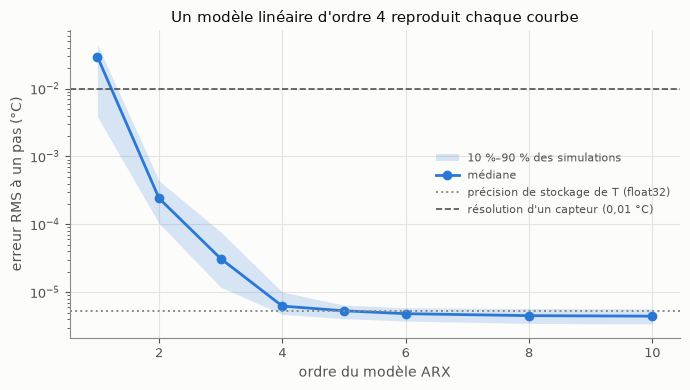

In [14]:
lin_test = load_json(RESULTS_DIR / "linearity.json")
fig = plots.arx_order_scan(lin_test["arx_order"], lin_test["float32_resolution_C"])

**Lecture.** Dès l'ordre 4, l'erreur atteint la précision avec laquelle T est stocké (≈ 5·10⁻⁶ °C), et elle ne
baisse plus ensuite. Le simulateur est donc **linéaire, invariant, d'ordre 4 environ, et sans bruit mesurable**.
L'information ne manque pas à cause du bruit.

### 6.3 Mais on ne peut pas en déduire le HLC

Si le modèle linéaire reproduit chaque courbe, son gain statique devrait donner le HLC ($\text{HLC} = P / G$) et ses
pôles les constantes de temps. On le vérifie sur les simulations chauffées.

In [15]:
ident = {f"ARX ordre {o}": {"MAPE HLC (%)": r["hlc"]["mape"],
                            "tau le plus lent, médiane (h)": r["tau_slowest_h"]["median"],
                            "corrélation avec tau_b": r["corr_log_tau_slowest_tau_b"]}
         for o, r in lin_test["arx_identification"].items()}
for m, r in lin_test["modes"].items():
    ident[f"{m} modes, tau libres"] = {"MAPE HLC (%)": r["hlc"]["mape"],
                                        "tau le plus lent, médiane (h)": r["tau_median_h"][0],
                                        "corrélation avec tau_b": np.nan}
pd.DataFrame(ident).T.round(2)

,MAPE HLC (%),"tau le plus lent, médiane (h)",corrélation avec tau_b
ARX ordre 2,121.79,2.50,-0.05
ARX ordre 3,274.73,3.19,0.06
ARX ordre 4,111.39,3.79,0.06
"4 modes, tau libres",214.59,107.96,NaN


**Lecture.** Les courbes sont reproduites au cent-millième de degré, et pourtant le HLC déduit est faux de plus de
100 %, et les constantes de temps identifiées (quelques heures) n'ont rien à voir avec les cibles (11 à 49 h). Sur
8 h, le début d'un mode lent ressemble presque à une droite dont la pente vaut gain / $\tau$ : **un bâtiment qui perd
beaucoup avec une grande inertie et un bâtiment qui perd peu avec une faible inertie produisent presque la même
courbe**. Le problème inverse est mal conditionné : l'information existe en théorie, mais elle est écrasée par
l'arrondi le plus fin.

### 6.4 Combien de bâtiments différents produisent la même courbe ?

Le signal de chauffage se répète d'un bâtiment à l'autre (graine PRBS fixe). Parmi les simulations qui partagent
exactement le même signal, on cherche pour chacune la plus proche voisine (écart quadratique moyen entre les courbes
T) et on compare leurs cibles. Analyse faite sur T exact, batches 11 à 16. Commande :
`uv run python -m thermal_id.identifiability`.

In [16]:
idf = load_json(RESULTS_DIR / "identifiability.json")
rows = {f"[{b['dist_min_C']:.2f} ; {b['dist_max_C']:.2f}) °C": {
            "simulations": b["n"], "part chauffées": b["frac_chauffees"],
            **{f"écart médian {t} (%)": b["ecart_relatif_median_pct"][t] for t in ("HLC", "HLC_ext", "tau_n")}}
        for b in idf["par_distance"]}
pd.DataFrame(rows).T.round(2).rename_axis("distance à la voisine")

,simulations,part chauffées,écart médian HLC (%),écart médian HLC_ext (%),écart médian tau_n (%)
distance à la voisine,,,,,
[0.00 ; 0.01) °C,23192.0,0.02,12.41,13.06,15.34
[0.01 ; 0.02) °C,4921.0,0.52,11.38,12.96,15.13
[0.02 ; 0.05) °C,61891.0,0.99,10.45,13.73,15.60
[0.05 ; 0.10) °C,139743.0,1.00,10.51,14.06,15.61
[0.10 ; 0.20) °C,55393.0,1.00,10.42,14.27,15.46
[0.20 ; 0.50) °C,12518.0,1.00,10.40,14.06,15.39
[0.50 ; 1.00) °C,1624.0,1.00,10.63,14.63,15.04
[1.00 ; inf) °C,568.0,1.00,13.92,16.14,16.53


**Lecture.** Deux courbes qui diffèrent de seulement 0,02 à 0,05 °C en moyenne correspondent à des HLC différents
d'environ 10 % (écart médian). Plus frappant : cet écart ne diminue presque pas quand les courbes se rapprochent
(environ 10,4 % entre 0,02 et 0,5 °C). Avec un capteur réel, aucun modèle ne peut séparer ces bâtiments à partir de
la seule courbe.

Cette analyse donne un ordre de grandeur, pas le plancher exact de l'erreur. La distance à la voisine dépend aussi de
la densité de l'échantillon (environ 130 bâtiments par signal U dans le train) ; et la tranche des courbes quasi
identiques (< 0,01 °C) contient presque uniquement des simulations sans chauffage, plus difficiles par nature.

### Synthèse

| Constat | Mesure |
|---|---|
| Les constantes de temps dépassent la fenêtre | on voit 15 % à 53 % de leur évolution en 8 h |
| Les données sont exactes et linéaires | ARX d'ordre 4 à la précision de stockage |
| L'inversion directe échoue | HLC faux de plus de 100 % malgré un ajustement parfait |
| Des bâtiments différents donnent presque la même courbe | voisines à 0,02–0,05 °C, HLC différents d'environ 10 % |

**Le plafond observé est donc physique** : il est fixé par la durée de la mesure, la forme du signal de chauffage et
la résolution du capteur, pas par le modèle. Un réseau plus gros ne crée pas l'information qui manque ; seul un
meilleur protocole de mesure peut l'apporter.

## 7. Limites et lien avec la méthode de coEnergy

### 7.1 Ce que fait coEnergy

L'article de référence de l'équipe (Nassif, Guernouti, Stabat, Cohen, prépublication SSRN 6928008) décrit une
méthode en deux phases :

1. **Au bureau** : générer une population de « jumeaux » du bâtiment cible (paramètres physiques tirés à ±60 %),
   simuler leurs réponses à des signaux PRBS ou sinusoïdaux avec la météo prévue, ajouter un bruit calibré sur les
   capteurs, entraîner un CNN-GRU, puis **choisir le signal de chauffage qui minimise l'erreur** (optimisation
   bayésienne).
2. **Sur site** : appliquer ce signal, mesurer la température, la météo et la puissance réelle, corriger les
   infiltrations, puis **réentraîner un modèle spécifique au test**, sur des simulations utilisant la météo et le
   chauffage réellement mesurés.

Résultat publié sur la cellule HAMEX (Cerema, Angers) : HLC à 2 W/K près (pour 23 W/K) en 6 h, contre 14 jours pour la
méthode de référence (co-heating).

### 7.2 Où se situe ce travail

Le modèle de ce projet correspond au **modèle de la phase 1** : un modèle généraliste, entraîné sur de nombreux
signaux de chauffage et sans météo variable. Nos résultats rejoignent les choix de l'article :
- la limite d'information sur 8 h explique pourquoi coEnergy **optimise le signal de chauffage** pour chaque test et
  **réentraîne un modèle spécialisé** : à scénario fixé, seul le bâtiment varie, et le problème devient plus simple
  (dans le notebook 2, à signal U fixé, une régression linéaire sur la courbe complète atteint un R² de 0,51 sur le
  HLC, contre 0,39 pour la baseline tous scénarios confondus) ;
- la section 5 montre qu'un modèle doit voir pendant l'entraînement la résolution et le bruit du capteur, ce que
  fait l'article.

### 7.3 Limites de ce travail

| Limite | Conséquence |
|---|---|
| Données simulées, une seule maison (`quentin_house`) et ses variantes | le modèle ne se transpose pas tel quel à un autre bâtiment |
| Aucune météo variable, pas de soleil, pas d'apports internes | sur site, ces perturbations seraient confondues avec la réponse du bâtiment |
| Pas d'infiltrations variables (vent) | le HLC apparent varierait pendant la mesure |
| Capteur idéal (seulement arrondi, sans bruit ni dérive) | un capteur réel est exact à ±0,25 °C environ ; il faudrait ajouter son bruit à l'entraînement |
| Une seule architecture principale, 400 000 simulations, 10 epochs | un gain modeste reste possible avec plus de données et un ensemble de modèles |
| Pas d'incertitude associée à chaque prédiction | impossible de savoir, pour un bâtiment donné, si la prédiction est fiable |

## 8. Conclusion et perspectives

**Ce qui a été obtenu.**
- Un modèle multi-indicateurs (CNN 1D, PyTorch) qui prédit à la fois HLC, $H_b$ et les trois constantes de temps, en
  respectant exactement $\text{HLC} = \text{HLC}_{mit} + \text{HLC}_{ext}$.
- Sur le test, avec la résolution de l'énoncé : MAPE de 8,4 % sur le HLC, 9,4 % sur HLC$_{ext}$, 15,8 % sur
  HLC$_{mit}$, et de 12 à 18 % sur les constantes de temps. C'est le meilleur des modèles comparés sur cinq cibles sur
  six.
- Une explication physique et chiffrée du plafond : 8 h de mesure ne suffisent pas à séparer pertes et inertie.

**Ce que ces résultats disent pour la mesure sur site.**
1. Avec 8 h de mesure, les constantes de temps ne sont pas identifiables de façon fiable : il faut des mesures plus
   longues, ou un signal de chauffage conçu pour elles.
2. Un modèle doit être entraîné avec la résolution et le bruit du capteur réel.
3. Le HLC est en partie mesurable en 8 h ; il faut l'accompagner d'une incertitude plutôt que d'une valeur seule.

**Perspectives**, de la plus directe à la plus ambitieuse :
1. **Prédire une incertitude** (moyenne et écart-type, vraisemblance gaussienne) pour signaler les cas ambigus.
2. **Mieux présenter les entrées** : dérivée de T, écart à la réponse moyenne au même signal U.
3. **Plus de données et un ensemble de modèles**, sur GPU.
4. **Ajouter les perturbations réelles** à l'entraînement (météo, soleil, infiltrations, bruit capteur), puis valider sur
   des bâtiments réels dont le HLC est connu par co-heating.
5. **Concevoir le signal de chauffage** pour maximiser l'information sur les constantes de temps, dans l'esprit de la
   phase 1 de la méthode de coEnergy.